[![Abrir no Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lalvim/DataMining/blob/main/notebooks/unidade_07/07_02_deteccao_univariada.ipynb)

# Unidade VII — Detecção de *Outliers*

## Detecção univariada

**Carga estimada:** 1 hora e 30 minutos  
**Pré-requisitos:** caracterização de outliers, estatística descritiva, visualização, NumPy e pandas.

> **Pergunta norteadora:** como sinalizar valores incomuns em uma variável sem transformar um limiar estatístico em diagnóstico automático?

Este notebook concentra-se em métodos **univariados**, nos quais cada atributo é examinado separadamente. Eles são transparentes e úteis para triagem, mas não detectam combinações incomuns entre variáveis.

## Objetivos de aprendizagem

Ao concluir este notebook, você será capaz de:

- calcular e interpretar escore-z e regra do intervalo interquartil;
- usar mediana e desvio absoluto mediano em uma análise robusta;
- comparar os alertas produzidos por diferentes limiares univariados;
- construir referências condicionais para populações ou períodos distintos;
- explicar pressupostos e limitações dos limiares estatísticos;
- propor uma investigação que preserve rastreabilidade e contexto.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 120})

## 1. Escore-z

Para observações $x_1,\ldots,x_n$, média $\bar{x}$ e desvio-padrão amostral $s$, o escore padronizado é

$$z_i=\frac{x_i-\bar{x}}{s},\qquad s=\sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2}. $$

O módulo $|z_i|$ expressa quantos desvios-padrão o valor está da média. Um limiar como 3 é uma convenção útil quando a distribuição é aproximadamente simétrica, unimodal e estável; não é uma lei universal. A própria média e o desvio-padrão são sensíveis a extremos.

In [2]:
tempos = pd.Series([10, 11, 10, 12, 9, 11, 10, 35], name="tempo_min")
media = tempos.mean()
desvio = tempos.std(ddof=1)
resultado_z = pd.DataFrame({
    "tempo_min": tempos,
    "z": (tempos - media) / desvio,
})
display(pd.DataFrame({"média": [media], "desvio_amostral": [desvio]}).round(3))
display(resultado_z.round(3))

,média,desvio_amostral
0,13.5,8.734


,tempo_min,z
0,10,-0.401
1,11,-0.286
2,10,-0.401
3,12,-0.172
4,9,-0.515
5,11,-0.286
6,10,-0.401
7,35,2.462


O valor 35 desloca a média e amplia o desvio-padrão; seu escore fica abaixo de 3 apesar da separação visível. O exemplo mostra o efeito de mascaramento: um extremo participa da construção da referência usada para julgá-lo.

## 2. Intervalo interquartil

Se $Q_1$ e $Q_3$ são o primeiro e o terceiro quartis, então

$$IQR=Q_3-Q_1.$$

A regra usual sinaliza valores fora das cercas

$$L=Q_1-1{,}5\,IQR,\qquad U=Q_3+1{,}5\,IQR.$$

Quartis são menos sensíveis a extremos que média e desvio-padrão. Ainda assim, a constante 1,5 é uma convenção exploratória. Distribuições assimétricas, grupos misturados e amostras pequenas exigem contexto e análise visual.

In [3]:
q1, q3 = tempos.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
resultado_iqr = pd.DataFrame({
    "tempo_min": tempos,
    "sinalizado_iqr": (tempos < limite_inferior) | (tempos > limite_superior),
})
display(pd.DataFrame({
    "Q1": [q1], "Q3": [q3], "IQR": [iqr],
    "limite_inferior": [limite_inferior],
    "limite_superior": [limite_superior],
}).round(3))
display(resultado_iqr)

,Q1,Q3,IQR,limite_inferior,limite_superior
0,10.0,11.25,1.25,8.125,13.125


,tempo_min,sinalizado_iqr
0,10,False
1,11,False
2,10,False
3,12,False
4,9,False
5,11,False
6,10,False
7,35,True


## 3. Mediana e MAD

O desvio absoluto mediano (*median absolute deviation*, MAD) é

$$MAD=\operatorname{mediana}_i\left(|x_i-\tilde{x}|\right),$$

em que $\tilde{x}$ é a mediana. Para dados aproximadamente normais, um escore-z robusto pode ser escrito como

$$z_i^{(r)}=0{,}6745\frac{x_i-\tilde{x}}{MAD}.$$

A constante 0,6745 coloca o escore em escala comparável ao escore-z sob normalidade. Se $MAD=0$, a fórmula não pode ser aplicada diretamente; é necessário tratar empates, aumentar a janela ou usar outra referência robusta.

,tempo_min,z,z_robusto,sinalizado_z,sinalizado_robusto,sinalizado_iqr
0,10,-0.401,-0.674,False,False,False
1,11,-0.286,0.674,False,False,False
2,10,-0.401,-0.674,False,False,False
3,12,-0.172,2.023,False,False,False
4,9,-0.515,-2.023,False,False,False
5,11,-0.286,0.674,False,False,False
6,10,-0.401,-0.674,False,False,False
7,35,2.462,33.050,False,True,True


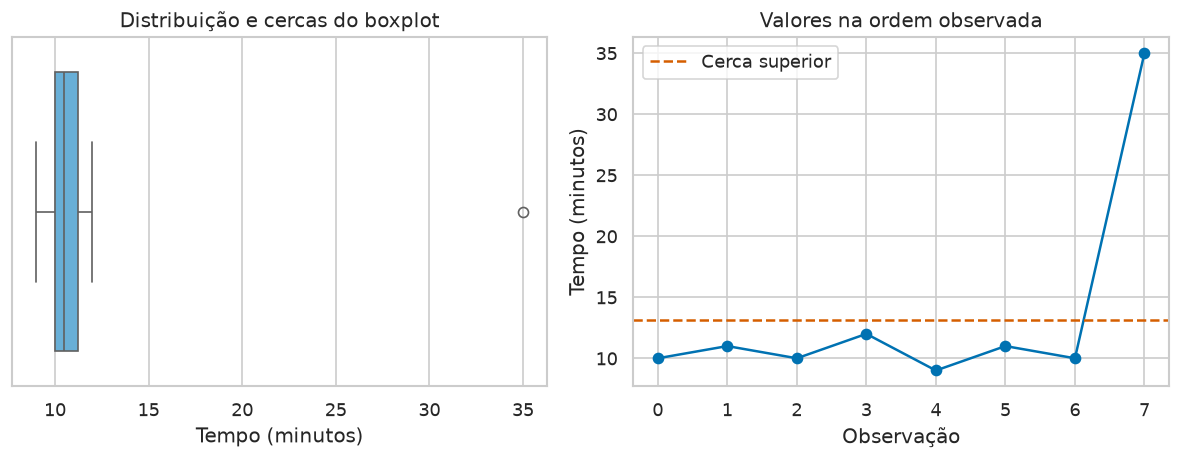

In [4]:
mediana = tempos.median()
mad = np.median(np.abs(tempos - mediana))
z_robusto = 0.6745 * (tempos - mediana) / mad
comparacao = resultado_z.assign(
    z_robusto=z_robusto,
    sinalizado_z=lambda df: df["z"].abs() > 3,
    sinalizado_robusto=lambda df: df["z_robusto"].abs() > 3.5,
    sinalizado_iqr=resultado_iqr["sinalizado_iqr"],
)
assert mad > 0
display(comparacao.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(x=tempos, ax=axes[0], color="#56B4E9")
axes[0].set(title="Distribuição e cercas do boxplot", xlabel="Tempo (minutos)")
axes[1].plot(tempos.index, tempos, marker="o", color="#0072B2")
axes[1].axhline(limite_superior, color="#D55E00", linestyle="--", label="Cerca superior")
axes[1].set(title="Valores na ordem observada", xlabel="Observação", ylabel="Tempo (minutos)")
axes[1].legend()
fig.tight_layout()
plt.show()

## 4. A referência deve respeitar o contexto

Um único limiar global pode confundir ciclos previsíveis com anomalias. No exemplo seguinte, a demanda diurna e a noturna têm níveis diferentes. Comparamos o valor à mediana e ao MAD da própria faixa de horário.

,periodo,consumo_kw,z_robusto_contextual,alerta_contextual
95,noite,8.0,7.248,True


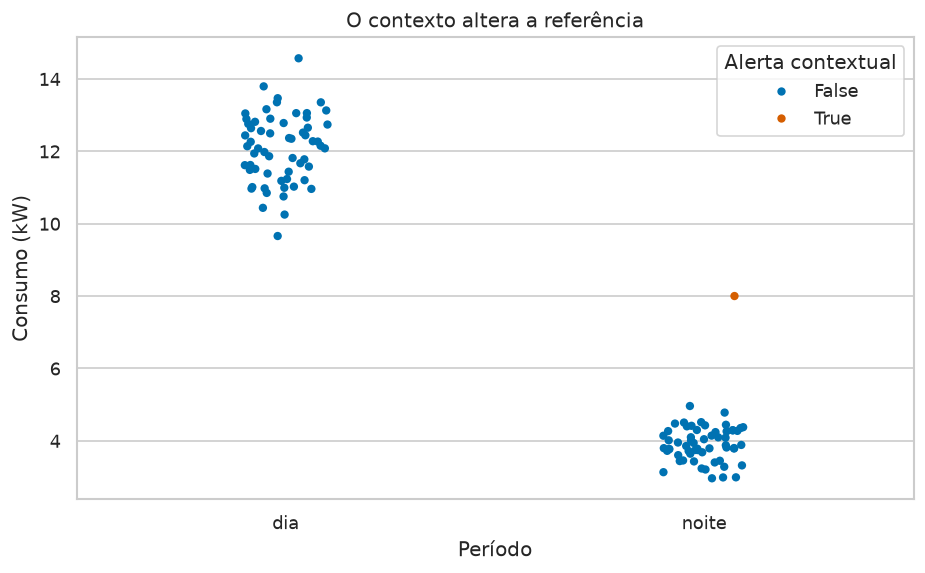

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
periodos = np.repeat(["dia", "noite"], 60)
consumo = np.concatenate([rng.normal(12, 1.2, 60), rng.normal(4, 0.6, 60)])
consumo[95] = 8.0
dados_contexto = pd.DataFrame({"periodo": periodos, "consumo_kw": consumo})

def escore_robusto(grupo: pd.Series) -> pd.Series:
    """Calcula escore robusto dentro de um contexto, preservando o índice."""
    centro = grupo.median()
    dispersao = np.median(np.abs(grupo - centro))
    if dispersao == 0:
        return pd.Series(np.nan, index=grupo.index)
    return 0.6745 * (grupo - centro) / dispersao

dados_contexto["z_robusto_contextual"] = (
    dados_contexto.groupby("periodo")["consumo_kw"].transform(escore_robusto)
)
dados_contexto["alerta_contextual"] = dados_contexto["z_robusto_contextual"].abs() > 3.5
display(dados_contexto.loc[dados_contexto["alerta_contextual"]].round(3))

ax = sns.stripplot(data=dados_contexto, x="periodo", y="consumo_kw", hue="alerta_contextual", palette={False: "#0072B2", True: "#D55E00"})
ax.set(title="O contexto altera a referência", xlabel="Período", ylabel="Consumo (kW)")
ax.legend(title="Alerta contextual")
plt.show()

## 5. Do alerta à decisão

Um protocolo defensável separa detecção e ação:

1. preservar o dado original e a unidade;
2. verificar coleta, integração e contexto operacional;
3. comparar métodos e limiares próximos;
4. priorizar por risco e capacidade de investigação;
5. registrar confirmação, falso alerta ou incerteza;
6. corrigir somente quando houver evidência do erro;
7. monitorar mudança da taxa e do perfil dos alertas.

Em decisões sobre pessoas, alertas não devem produzir sanções automáticas. É necessário oferecer revisão, limitar acesso e avaliar impactos desiguais.

## 6. Quando usar cada método?

A escolha depende da forma da distribuição, da resistência necessária a extremos e da existência de contextos distintos. A tabela resume pontos de partida, não regras automáticas.

| Método | Recomendado quando | Pressuposto ou força principal | Evite usar isoladamente quando |
|---|---|---|---|
| histograma e boxplot | a análise é exploratória e se deseja verificar caudas, assimetria e grupos | tornam a forma da distribuição visível antes de escolher um limiar | há muitos registros, várias populações misturadas ou necessidade de decisão reproduzível |
| escore-z | os dados são aproximadamente simétricos, unimodais e estáveis | distância à média expressa em desvios-padrão | há forte assimetria, caudas pesadas, multimodalidade ou extremos que deslocam média e desvio |
| regra do IQR | deseja-se uma triagem simples e resistente a poucos extremos, sem supor normalidade | quartis reduzem a influência das caudas | a assimetria é substantiva, a amostra é pequena ou diferentes contextos foram misturados |
| escore robusto por mediana e MAD | há contaminação moderada e se deseja um escore por observação | centro e dispersão são resistentes a extremos | o MAD é zero, existem muitos empates ou a distribuição possui vários regimes |
| limites por contexto ou grupo | horário, estação, equipamento ou população altera o nível esperado | compara cada observação com uma referência substantivamente comparável | os grupos têm poucos dados, foram definidos depois de observar os alertas ou escondem mudança real |

Uma prática recomendada é começar pela visualização, justificar a referência, comparar pelo menos um método clássico e um robusto e relatar como os alertas mudam sob limiares próximos. Se a anomalia depende da combinação entre atributos, os métodos deste notebook não bastam; use uma abordagem multivariada.

## 7. Atividades

**U07-NB02-V01.** Um gasto de R$ 900 é comum para uma empresa e raro para uma pessoa física. Classifique o caso quanto ao tipo de anomalia e explique por que um limiar global pode falhar.

**U07-NB02-E01.** Para os valores `[4, 5, 5, 6, 6, 7, 30]`, calcule $Q_1$, $Q_3$, IQR e as cercas pelo método de interpolação linear usado pelo pandas. Identifique os valores sinalizados.

**U07-NB02-E02.** Compare média/desvio-padrão e mediana/MAD quanto à influência de extremos. Explique uma situação em que a regra robusta ainda produziria conclusão inadequada.

**U07-NB02-E03.** Uma série de 100 leituras contém um valor sinalizado. Proponha um fluxo de investigação que diferencie falha de sensor, mudança operacional e evento raro legítimo, sem apagar o registro original.

**U07-NB02-E04.** Modifique o limiar do escore robusto contextual de 3,5 para 3 e 4. Compare a quantidade de alertas e discuta o compromisso entre sensibilidade e carga de investigação.

## 8. Síntese

- *Outlier* é uma observação incomum em relação a uma referência explícita.
- Anomalias podem ser globais, contextuais ou coletivas e possuir causas distintas.
- Escore-z depende de média e desvio-padrão; IQR e MAD são mais robustos, mas não universais.
- Limiar, contexto, escala e janela determinam quais objetos recebem alerta.
- Detectar, diagnosticar e decidir são etapas diferentes; nenhuma regra justifica exclusão automática.

## Referências

- HAN, J.; PEI, J.; TONG, H. *Data Mining: Concepts and Techniques*. 4. ed. Morgan Kaufmann, 2023. Cap. 11.
- AGGARWAL, C. C. *Outlier Analysis*. 2. ed. Springer, 2017.
- TUKEY, J. W. *Exploratory Data Analysis*. Addison-Wesley, 1977.

Os dados e as figuras deste notebook são sintéticos e autorais.